# Task 4-5 — Video Classification (Frames → CNN + Temporal Pooling)

**Dataset:** UCF101 subset (5 classes × 20 videos). Frames extracted with FFmpeg.

**Goal:** Build a tf.data pipeline that samples fixed-length frame sequences per video and trains a small baseline model.


In [2]:
# ================================
# Imports & Configuration
# ================================

import os
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths
BASE_DIR = os.getcwd()
INDEX_CSV = os.path.join(BASE_DIR, "outputs", "index.csv")

print("TensorFlow:", tf.__version__)
print("Index path:", INDEX_CSV)

# Load index
df = pd.read_csv(INDEX_CSV)
print("Total videos:", len(df))
print("Classes:", df["label"].unique())
df.head()


TensorFlow: 2.20.0
Index path: E:\JYU\Deep-Learning for Cognitive Computing for Developers\Task 4\Task4-5_Video_Classification\outputs\index.csv
Total videos: 100
Classes: ['BasketballDunk' 'Biking' 'CliffDiving' 'HorseRiding' 'WalkingWithDog']


,frame_dir,label,nframes
0,E:\JYU\Deep-Learning for Cognitive Computing f...,BasketballDunk,12
1,E:\JYU\Deep-Learning for Cognitive Computing f...,BasketballDunk,13
2,E:\JYU\Deep-Learning for Cognitive Computing f...,BasketballDunk,14
3,E:\JYU\Deep-Learning for Cognitive Computing f...,BasketballDunk,12
4,E:\JYU\Deep-Learning for Cognitive Computing f...,BasketballDunk,13


In [3]:
# ================================
# Encode labels + split
# ================================

# Map labels -> int
classes = sorted(df["label"].unique().tolist())
class_to_id = {c:i for i,c in enumerate(classes)}
id_to_class = {i:c for c,i in class_to_id.items()}

df["label_id"] = df["label"].map(class_to_id)

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df["label_id"]
)

print("Classes:", classes)
print("Train:", len(train_df), "Val:", len(val_df))
print("Train class counts:\n", train_df["label"].value_counts())
print("Val class counts:\n", val_df["label"].value_counts())


Classes: ['BasketballDunk', 'Biking', 'CliffDiving', 'HorseRiding', 'WalkingWithDog']
Train: 80 Val: 20
Train class counts:
 label
WalkingWithDog    16
HorseRiding       16
CliffDiving       16
Biking            16
BasketballDunk    16
Name: count, dtype: int64
Val class counts:
 label
CliffDiving       4
BasketballDunk    4
HorseRiding       4
Biking            4
WalkingWithDog    4
Name: count, dtype: int64


In [6]:
# ================================
# tf.data loader (graph-safe via numpy_function)
# ================================

import glob
import cv2

IMG_SIZE = 160
SEQ_LEN  = 12
BATCH    = 8
AUTOTUNE = tf.data.AUTOTUNE

def _load_frames_numpy(frame_dir_bytes, seq_len=SEQ_LEN, img_size=IMG_SIZE):
    frame_dir = frame_dir_bytes.decode("utf-8")
    paths = sorted(glob.glob(os.path.join(frame_dir, "*.jpg")))

    # if too few frames, repeat last frame
    if len(paths) == 0:
        # should not happen, but safe fallback
        x = np.zeros((seq_len, img_size, img_size, 3), dtype=np.float32)
        return x

    idx = np.linspace(0, len(paths) - 1, seq_len).round().astype(int)
    idx = np.clip(idx, 0, len(paths) - 1)

    frames = []
    for i in idx:
        img = cv2.imread(paths[i])          # BGR
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (img_size, img_size))
        img = img.astype(np.float32) / 255.0
        frames.append(img)

    return np.stack(frames, axis=0).astype(np.float32)  # (T,H,W,3)

def load_video_frames(frame_dir):
    x = tf.numpy_function(_load_frames_numpy, [frame_dir], Tout=tf.float32)
    x.set_shape((SEQ_LEN, IMG_SIZE, IMG_SIZE, 3))
    return x

def make_ds(df_):
    frame_dirs = df_["frame_dir"].astype(str).tolist()
    labels     = df_["label_id"].astype(int).tolist()

    ds = tf.data.Dataset.from_tensor_slices((frame_dirs, labels))
    ds = ds.map(lambda d,y: (load_video_frames(d), y), num_parallel_calls=AUTOTUNE)
    ds = ds.shuffle(200, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)

x, y = next(iter(train_ds))
print("Batch X:", x.shape, "dtype:", x.dtype)
print("Batch y:", y.shape, "min/max:", int(tf.reduce_min(y)), int(tf.reduce_max(y)))

Batch X: (8, 12, 160, 160, 3) dtype: <dtype: 'float32'>
Batch y: (8,) min/max: 0 3


In [7]:
# ================================
# Model (CNN per-frame + temporal average)
# ================================

NUM_CLASSES = len(classes)

inp = tf.keras.Input(shape=(SEQ_LEN, IMG_SIZE, IMG_SIZE, 3))

# Per-frame CNN
x = tf.keras.layers.TimeDistributed(
    tf.keras.Sequential([
        tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same"),
        tf.keras.layers.MaxPool2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
        tf.keras.layers.MaxPool2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
        tf.keras.layers.GlobalAveragePooling2D(),
    ])
)(inp)  # (B, T, F)

# Temporal pooling
x = tf.keras.layers.GlobalAveragePooling1D()(x)

x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inp, out)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 12, 160, 160, 3)     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 12, 64)              │          23,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,069 (109.64 KB)

 Trainable params: 28,069 (109.64 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# ================================
# Train + save best
# ================================

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join("outputs", "models", "best_task45.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

print("Best val acc:", max(history.history["val_accuracy"]))


Epoch 1/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - accuracy: 0.2436 - loss: 1.6030
Epoch 1: val_accuracy improved from None to 0.20000, saving model to outputs\models\best_task45.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 577ms/step - accuracy: 0.1875 - loss: 1.6139 - val_accuracy: 0.2000 - val_loss: 1.6069
Epoch 2/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.1513 - loss: 1.6002
Epoch 2: val_accuracy did not improve from 0.20000
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 462ms/step - accuracy: 0.1750 - loss: 1.6136 - val_accuracy: 0.2000 - val_loss: 1.6067
Epoch 3/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - accuracy: 0.2149 - loss: 1.5989
Epoch 3: val_accuracy improved from 0.20000 to 0.25000, saving model to outputs\models\best_task45.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 456ms/step - accuracy: 0.2375 - loss: 1.5989 - val_accuracy: 0.2500 - val_loss: 1.6014
Epoch 4/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.2179 - loss: 1.5853
Epoch 4: val_accuracy did not improve from 0.2

In [9]:
# ================================
# Evaluate + confusion matrix + save report
# ================================

from sklearn.metrics import classification_report, confusion_matrix

# Predict on val
y_true = []
y_pred = []

for xb, yb in val_ds:
    p = model.predict(xb, verbose=0)
    y_true.extend(yb.numpy().tolist())
    y_pred.extend(np.argmax(p, axis=1).tolist())

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

report = classification_report(
    y_true, y_pred,
    target_names=classes,
    digits=4
)
print(report)

# Save report
os.makedirs(os.path.join("outputs","reports"), exist_ok=True)
with open(os.path.join("outputs","reports","classification_report.txt"), "w", encoding="utf-8") as f:
    f.write("Classes: " + str(classes) + "\n\n")
    f.write("Confusion Matrix:\n" + str(cm) + "\n\n")
    f.write(report)

print("Saved: outputs/reports/classification_report.txt")


Confusion Matrix:
 [[0 4 0 0 0]
 [0 4 0 0 0]
 [0 4 0 0 0]
 [0 3 0 0 1]
 [0 3 0 0 1]]
                precision    recall  f1-score   support

BasketballDunk     0.0000    0.0000    0.0000         4
        Biking     0.2222    1.0000    0.3636         4
   CliffDiving     0.0000    0.0000    0.0000         4
   HorseRiding     0.0000    0.0000    0.0000         4
WalkingWithDog     0.5000    0.2500    0.3333         4

      accuracy                         0.2500        20
     macro avg     0.1444    0.2500    0.1394        20
  weighted avg     0.1444    0.2500    0.1394        20

Saved: outputs/reports/classification_report.txt


E:\JYU\Deep-Learning for Cognitive Computing for Developers\Task 4\Task4-5_Video_Classification\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
E:\JYU\Deep-Learning for Cognitive Computing for Developers\Task 4\Task4-5_Video_Classification\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
E:\JYU\Deep-Learning for Cognitive Computing for Developers\Task 4\Task4-5_Video_Classification\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is 

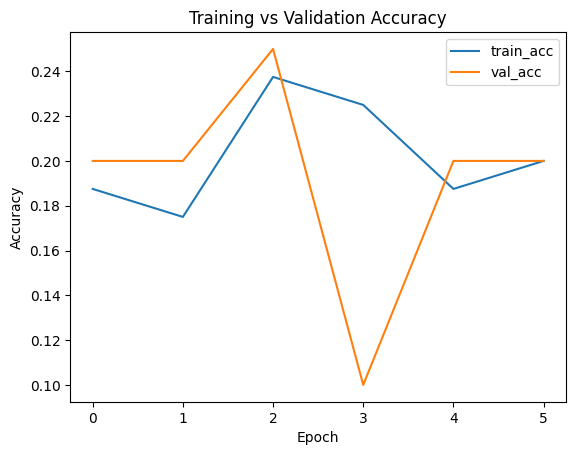

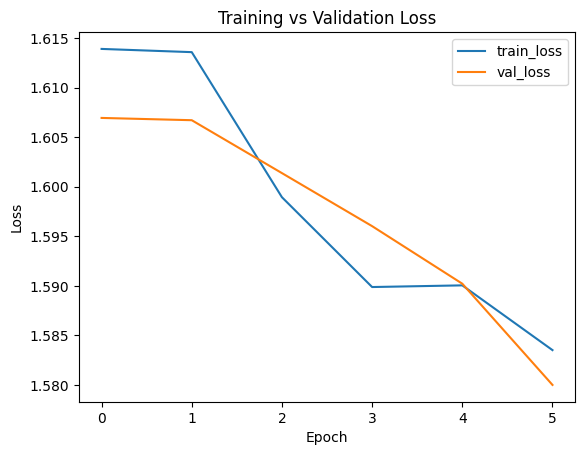

Saved: outputs/reports/acc_curve.png and outputs/reports/loss_curve.png


In [10]:
# ================================
# Plot training curves
# ================================

import matplotlib.pyplot as plt
import os

os.makedirs(os.path.join("outputs", "reports"), exist_ok=True)

plt.figure()
plt.plot(history.history["accuracy"], label="train_acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training vs Validation Accuracy")
plt.savefig(os.path.join("outputs", "reports", "acc_curve.png"), dpi=200)
plt.show()

plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.savefig(os.path.join("outputs", "reports", "loss_curve.png"), dpi=200)
plt.show()

print("Saved:", "outputs/reports/acc_curve.png", "and", "outputs/reports/loss_curve.png")


In [11]:
# ================================
# Improved Model — CNN + LSTM (temporal modeling)
# ================================

NUM_CLASSES = len(classes)

inp = tf.keras.Input(shape=(SEQ_LEN, IMG_SIZE, IMG_SIZE, 3))

# Per-frame CNN feature extractor
frame_cnn = tf.keras.Sequential([
    tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.GlobalAveragePooling2D(),
], name="frame_cnn")

x = tf.keras.layers.TimeDistributed(frame_cnn)(inp)     # (B, T, F=64)

# Temporal modeling
x = tf.keras.layers.LSTM(64, return_sequences=False)(x) # (B, 64)

x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(0.4)(x)
out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model_lstm = tf.keras.Model(inp, out, name="cnn_lstm")
model_lstm.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_lstm.summary()

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 12, 160, 160, 3)     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 12, 64)              │          23,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 61,093 (238.64 KB)

 Trainable params: 61,093 (238.64 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ================================
# Train Improved Model
# ================================

callbacks_lstm = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join("outputs", "models", "best_task45_lstm.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True
    )
]

history_lstm = model_lstm.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_lstm
)

print("Best LSTM val acc:", max(history_lstm.history["val_accuracy"]))

Epoch 1/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.1697 - loss: 1.6013
Epoch 1: val_accuracy improved from None to 0.20000, saving model to outputs\models\best_task45_lstm.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 515ms/step - accuracy: 0.1625 - loss: 1.6160 - val_accuracy: 0.2000 - val_loss: 1.5977
Epoch 2/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.2489 - loss: 1.5901
Epoch 2: val_accuracy did not improve from 0.20000
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 430ms/step - accuracy: 0.1875 - loss: 1.6158 - val_accuracy: 0.2000 - val_loss: 1.6010
Epoch 3/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.2125 - loss: 1.5997
Epoch 3: val_accuracy improved from 0.20000 to 0.35000, saving model to outputs\models\best_task45_lstm.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 448ms/step - accuracy: 0.1875 - loss: 1.6042 - val_accuracy: 0.3500 - val_loss: 1.5988
Epoch 4/15
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - accuracy: 0.1324 - loss: 1.6049
Epoch 4: val_accuracy did not improv

In [13]:
# ================================
# Evaluate LSTM + save report
# ================================

from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for xb, yb in val_ds:
    p = model_lstm.predict(xb, verbose=0)
    y_true.extend(yb.numpy().tolist())
    y_pred.extend(np.argmax(p, axis=1).tolist())

cm_lstm = confusion_matrix(y_true, y_pred)
print("LSTM Confusion Matrix:\n", cm_lstm)

report_lstm = classification_report(
    y_true, y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
)
print(report_lstm)

with open(os.path.join("outputs","reports","classification_report_lstm.txt"), "w", encoding="utf-8") as f:
    f.write("Classes: " + str(classes) + "\n\n")
    f.write("LSTM Confusion Matrix:\n" + str(cm_lstm) + "\n\n")
    f.write(report_lstm)

print("Saved: outputs/reports/classification_report_lstm.txt")

LSTM Confusion Matrix:
 [[4 0 0 0 0]
 [1 3 0 0 0]
 [4 0 0 0 0]
 [2 2 0 0 0]
 [1 3 0 0 0]]
                precision    recall  f1-score   support

BasketballDunk     0.3333    1.0000    0.5000         4
        Biking     0.3750    0.7500    0.5000         4
   CliffDiving     0.0000    0.0000    0.0000         4
   HorseRiding     0.0000    0.0000    0.0000         4
WalkingWithDog     0.0000    0.0000    0.0000         4

      accuracy                         0.3500        20
     macro avg     0.1417    0.3500    0.2000        20
  weighted avg     0.1417    0.3500    0.2000        20

Saved: outputs/reports/classification_report_lstm.txt
